# Sampling any Bayesian model by walking a graph

Overview
1. Specify/write the model
2. Model is parsed into DAG (Directed Acyclic Graph)
3. Choose a sampling algorithm for each parameter or parameter group (bijector into adaptive Random Walk Metropolis Hastings)
4. Update steps are chained together into a Metropolis-Within-Gibbs kernel
5. Construct the joint log-density function - sum of log probabilities
6. Assemble and compile MCMC chain
7. Run compiled JAX jit chain, which approximates the posterior
8. Results, measures, traceplots and density plots

## Bayesian inference
Bayesian inference allows us to estimate unknown model parameters by combining prior knowledge with observed data. The result is a posterior distribution which describes the uncertainty about the parameters after inferring from the data. Bayes Theorem states that:

\begin{equation}
P(A \mid B) = \frac{P(B \mid A) P(A)}{P(B)} \tag{1}
\end{equation}

- Posterior: $P(A \mid B)$ of interest; updated distribution of parameters after observing data
- Prior: $P(A)$; probability distribution of prior parameters (e.g. pdf/pmf)
- Likelihood: $P(B \mid A)$; probability of observing event B if event A is true

For a fixed dataset, the evidence does not depend on the unknown parameters. Consequently, the posterior is proportional to the product of the likelihood and the prior:
$P(A \mid B)\propto P(B\mid A) P(B).$ Thus we do not need to know what the marginal probability $P(B)$ is.

Inference on infectious disease outbreaks can be performed by Bayesian modelling to gain knowledge such as the rate of spread, duration of infection and verify various hypotheses. In this project, the model is represented as a directed acyclic graph (DAG). Each stochastic node has a probability distribution conditional on its parent nodes. The prior distributions describe the unknown parameters, while the observation nodes contribute the likelihood.

How does observed data fit into this? Given observed data $y_i$, and k prior parameters $A_1, A_2,..., A_k$, the expression for the joint density would be as follows

\begin{equation}
P(A_1,..., A_k,y) = \underbrace{P(A_1)P(...)P(A_k)}_{priors} \underbrace{\prod_i P(y_i\mid A_1, ... ,A_k)}_{likelihood} \tag{2}
\end{equation}

The posterior distribution of the parameters, conditional on the observed data, is proportional to this joint density.

We may choose to calculate the joint log-density instead to prevent numerical instability as we may be dealing with very small numbers. Multiplying small fractions quickly approaches 0, causing a problem called underflow (value too small for computer assigned data type). Data types that hold numbers have a limited precision, determined by the amount of memory allocated to it. 

\begin{equation}
\log P(A_1,..., A_k,y)=\log P(A_1)+\log P(...)+\log P(A_k)+\sum_i\log P(y_i\mid A_1, ... ,A_k) \tag{3}
\end{equation}


## Metropolis–Hastings random walk

The Metropolis–Hastings (MH) algorithm is a Markov chain Monte Carlo (MCMC) method used to generate samples from a target distribution, such as the posterior distribution of the model parameters.

Let $\theta = A_1, A_2, ... , A_k$ for ease of notation.

In this project, the target distribution is the posterior density, up to a normalising constant:

$\pi(\theta)\propto p(y\mid\theta)p(\theta)$

The sampler does not need to know the normalising constant or calculate the posterior density explicitly. It only needs to evaluate the target log density at the current and proposed parameter values.

At each iteration, the algorithm proposes a new state $\theta'$ using a proposal distribution $q(\theta'\mid\theta)$, where $\theta$ is the current state. The proposal is then accepted or rejected according to the Metropolis–Hastings acceptance probability:

\begin{equation}
a(\theta,\theta')=\min(1,\,\frac{\pi(\theta')}{\pi(\theta)}\frac{q(\theta\mid\theta')}{q(\theta'\mid\theta)}) \tag{4}
\end{equation}

The proposal correction accounts for the possibility that a move from $\theta$ to $\theta'$ is not as likely as the reverse move.

### Random walk proposals

A random walk proposes a new state by perturbing the current parameter value:

$\theta'=\theta+\varepsilon$

where $\varepsilon$ is a random perturbation, often drawn from a zero-centred Normal distribution.

For a symmetric proposal, the probability of proposing $\theta'$ from $\theta$ equals the probability of proposing $\theta$ from $\theta'$. Therefore,

$q(\theta'\mid\theta)=q(\theta\mid\theta'),$

and the proposal terms cancel. The acceptance probability simplifies to

\begin{equation}
a(\theta,\theta')=\min\left(1,\frac{\pi(\theta')}{\pi(\theta)}\right) \tag{5}
\end{equation}

As we are evaluating the log density, this can equivalently be written as

\begin{equation}
a(\theta,\theta')=\min\left(1,\exp\left[\log\pi(\theta')-\log\pi(\theta)\right]\right) \tag{6}
\end{equation}

In practice, the algorithm accepts every proposal that increases the target density. A proposal that decreases the target density can still be accepted, with a probability determined by the ratio of the proposed and current densities. This allows the chain to explore the distribution rather than becoming trapped at a local maximum.

### Sampling procedure

For each parameter or block of parameters, the sampler follows these steps:

1. Start from the current parameter values.
2. Generate a proposed value using the random walk proposal.
3. Evaluate the joint log density at the proposed state and compare it with the current state's log density.
4. Accept the proposal with the Metropolis–Hastings acceptance probability; otherwise, retain the current state.
5. Record the resulting state and repeat.

The difference between the proposed and current log densities is sufficient for the acceptance decision. The normalising constant in Bayes' theorem cancels, so the sampler does not need to evaluate the marginal likelihood.

### Application in this project

The implementation uses `gemlib.mcmc.adaptive_rwmh()` to construct an adaptive random walk Metropolis–Hastings sampler. The sampler is applied through a Metropolis-within-Gibbs scheme: parameters are updated one at a time by default, or in blocks when they are explicitly grouped.

For each proposal, the joint log density is reevaluated using the current values of the other parameters and the observed data. This accounts for the dependencies between nodes in the model.

Some parameters have restricted support. For example, $\sigma$ must be positive because it represents a standard deviation. The implementation uses an exponential bijector for Gamma, Exponential and LogNormal nodes, allowing the random walk to operate on an unconstrained real-valued scale while mapping proposals back to positive values.

The sampler generates a chain of parameter values. Initial iterations may be discarded as warm-up, particularly when adaptation is being used. The remaining draws can be used to estimate posterior means, uncertainty intervals and other quantities of interest. Trace plots and effective sample sizes help assess how well the chain has explored the target distribution.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow_probability.substrates.jax as tfp
from scipy import stats

from distributions import Gamma, Normal
from samplers import blocks, dfs_nodes, log_density, run

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
np.set_printoptions(linewidth=200)

DRAWS = 20_000  #sweeps per chain
BURN = 5_000  #discarded while the sampler tunes itself

def summarise(samples, burn=BURN, truth=None):
    #Posterior mean, spread, and how many independent draws we got
    print(f"{'':7s}{'mean':>9s}{'sd':>9s}{'ESS':>8s}{'MC err':>9s}" + ("   truth" if truth else ""))
    out = {}
    for name, draws in samples._asdict().items():
        d = np.asarray(draws)[burn:]
        ess = float(tfp.mcmc.effective_sample_size(d))
        out[name] = (d.mean(), d.std(), ess)
        line = f"{name:7s}{d.mean():9.4f}{d.std():9.4f}{ess:8.0f}{d.std() / np.sqrt(ess):9.4f}"
        print(line + (f"   {truth[name]:.3f}" if truth else ""))
    return out


def plot_trace(samples, burn=BURN, truth=None, title=None):
    #Left: the walk itself
    #Right: how often each value was visited, density
    names = list(samples._asdict())
    fig, axes = plt.subplots(
        len(names), 2, figsize=(11, 1.9 * len(names)),
        gridspec_kw={"width_ratios": [3, 1]}, squeeze=False,
    )
    for row, name in enumerate(names):
        d = np.asarray(getattr(samples, name))[burn:]
        axes[row, 0].plot(d, linewidth=0.4, color="steelblue")
        axes[row, 0].set(ylabel=name, xlabel="sweep" if row == len(names) - 1 else "")
        sns.kdeplot(y=d, ax=axes[row, 1], fill=True, color="steelblue")
        axes[row, 1].set(xlabel="", ylabel="", yticklabels=[])
        if truth and name in truth:
            for ax in axes[row]:
                ax.axhline(truth[name], color="crimson", ls="--", lw=1)
    if title:
        fig.suptitle(title, y=1.002, fontsize=11)
    fig.tight_layout()
    return fig


## Model

Growth could be assumed to be exponential in a susceptible population. Suppose you know the number of new infections for a few days over a period. You might be interested finding out the rate of infection or number of initial cases. Let $C(t)$ be the number of new infections on day t, r the daily growth rate of infection and A a constant.

$$C(t) = Ae^{rt}$$

Case counts growing (or shrinking) at a roughly constant rate look like a straight line in log space.

$$\log C(t) = \log(A) + rt$$

so this "toy" linear regression is exactly the standard log-linear model for the exponential phase of an outbreak. $\log(A)$ is the value of the intercept, and thus can be interpreted as the log(initial cases). Similarly, r can be interpreted as the slope, daily growth rate of the log(cases).

Of the data, let $x_i$ be day number and $y_i$ be $\log(\text{daily cases})$. We expect that our observations are not perfect, and contain a degree of noise due to imperfect reporting and analogue/ambiguous incubation periods. It would be sensible to account for this. A model can be constructed as follows...

$$
\begin{aligned}
\alpha &\sim \mathrm{Normal}(0,\ 1) && \text{log(cases) on the initial day} \\
\beta &\sim \mathrm{Normal}(0,\ 1) && \text{daily growth rate of log(cases)} \\
\sigma &\sim \mathrm{Gamma}(1,\ 1) && \text{noise size, must be positive} \\[4pt]
\mu_i &= \alpha + \beta\,(x_i) && \text{the line itself}\\
y_i &\sim \mathrm{Normal}(\mu_i,\ \sigma) && \text{what we observe}
\end{aligned}
$$

The first three parameters $\alpha, \beta, \sigma$ are our priors. We have the likelihood $y_i$, which applies noise $\sigma$ to the deterministic expression for the log-linear model $\mu_i$. We choose $\sigma$ to be Gamma distributed, as we know the noise to be a positive value.

- $x_i - \bar{x}$ centres $\alpha$

| symbol | statistical role | epidemiological meaning |
|---|---|---|
| $x_i$ | predictor | day number |
| $y_i$ (observed) | response | $\log(\text{daily cases on day } x_i)$ |
| $\beta$ | slope | exponential growth rate $r$. Doubling time $=\ln(2)/\beta$ ($\beta<0$ = decline, halving time $=\ln(2)/|\beta|$). Roughly linked to the reproduction number via the generation interval $T$: $R \approx e^{\beta T}$ |
| $\alpha$ | intercept | $\log(\text{cases})$ on the initial day |
| $\mu_i$ | fitted trend | the modelled exponential growth curve, in log space |
| $\sigma$ | residual scale | noise around the exponential trend |



In [2]:
#Generate data
TRUE_ALPHA_DAY0 = np.log(5)  #log(daily cases): there were 5 initial cases on day 1
TRUE_BETA = 0.15  #daily exponential growth rate: doubling time = ln(2)/0.15 ~= 4.6 days
TRUE_SIGMA = 0.25  #residual noise

x_i = np.arange(1, 31)  #day number, 30 days of surveillance
rng = np.random.default_rng(2)
y_obs = TRUE_ALPHA_DAY0 + TRUE_BETA * x_i + rng.normal(0.0, TRUE_SIGMA, x_i.shape) #log(daily cases)

In [3]:
#The model
alpha = Normal(0.0, 1.0)
beta = Normal(0.0, 1.0)
sigma = Gamma(1.0, 1.0)

mu_i = alpha + beta * x_i
y_i = Normal(mu_i, sigma)

print("day =", x_i)
print("log(cases) =", y_obs.round(3))
print("cases (approx) =", np.exp(y_obs).round(1))
print("\nthe model:", y_i)

day = [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30]
log(cases) = [1.807 1.779 1.956 1.599 2.809 2.795 2.578 3.003 3.03  2.971 3.504 3.332 3.477 3.511 3.973 3.985 4.296 4.158 4.491 4.386 4.97  4.956 5.142 5.312 5.107 5.705 6.174 5.4   5.527 5.733]
cases (approx) = [  6.1   5.9   7.1   4.9  16.6  16.4  13.2  20.1  20.7  19.5  33.2  28.   32.4  33.5  53.2  53.8  73.4  63.9  89.2  80.3 144.  142.1 171.1 202.8 165.1 300.4 479.9 221.4 251.4 309. ]

the model: Normal((Normal(0.0, 1.0) + (Normal(0.0, 1.0) * [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30])), Gamma(1.0, 1.0))


## Model to Directed Acyclic Graph

Classes are blueprints or templates that define a certain structure or behaviour, and are particularly useful to organise and create objects that are similar. It can capture relationships between classes of objects. In our case, we wish to define a family of classes that represent distributions, and can thus share behaviours and functions where it is appropriate. This structure clearly has a strong hierarchical inheritance relationship, i.e. a Normal distribution 'is a' Continuous Distribution, and a Continuous Distribution 'is-a' Distribution. The fact that a distribution is Normal, or that it is continuous is useful information to us, as that affects the transformations/bijectors or samplers that we would choose to run inference on that node. This is defined in [distributions.py](distributions.py).

```
Distribution ── Discrete
          │     └────────── ... Not yet implemented ... (Binomial, Geometric, Poisson, etc.)
          ├──── Continuous
          │     └────────── Normal
          │     └────────── Gamma
          │     └────────── Exponential
          │     └────────── LogNormal
          │     └────────── ...
          └──── Logical

```

A node in a Directed Acylic Graph can be a single random variable (a variant of a discrete or continuous distribution), data, or a composition of random variables and/or data. To handle an expression of variables and data, the Logical node is introduced.

Expressions including `+` / `*` return `Logical` nodes, which have a left and right operand. As there is a limit of two operands, larger expressions are compounded into several Logical nodes. In the case of a + bx, that expression would be parsed into: `Logical(+, a, Logical(*,b,x))`. This is a strong 'composition' relationship. 

The addition and multiplication operators are overwritten for any objects that are of or inherit from the Distribution class, such that a Logical object is returned when it is performed.

```python
Distribution.__add__, Distribution.__radd__ = _wrap(operator.add, "+")
```

Thus the code (see cell 31) that defines the model is automatically parsed into a directed acyclic graph. Our log-linear regression is structured as follows.

```
alpha ─────────────────────────┐
                               ├── (+) ──▶ μ_i ──┐
beta ────┐                     │                 ├──▶ y_i  ◀── y_obs
         ├── (*) ──▶ β(x_i-x̄)─┘                 │
x_i-x̄ ───┘                                       │
sigma ───────────────────────────────────────────┘
```
The tree is 'walked' and `dfs_nodes` returns a list of nodes, ordered by parents before children.


In [4]:
print(f"mu_i is a {type(mu_i).__name__} node, holding the expression {mu_i}")
print(f"y_i's parameters: {y_i.parameters}")

print("\ndfs_nodes(y_i) walks the graph, keeping only the stochastic nodes:")
for position, node in enumerate(dfs_nodes(y_i)):
    print(f"  {position}. {type(node).__name__:6s} {node}")

mu_i is a Logical node, holding the expression (Normal(0.0, 1.0) + (Normal(0.0, 1.0) * [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30]))
y_i's parameters: [(Normal(0.0, 1.0) + (Normal(0.0, 1.0) * [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30])), Gamma(1.0, 1.0)]

dfs_nodes(y_i) walks the graph, keeping only the stochastic nodes:
  0. Normal Normal(0.0, 1.0)
  1. Normal Normal(0.0, 1.0)
  2. Gamma  Gamma(1.0, 1.0)
  3. Normal Normal((Normal(0.0, 1.0) + (Normal(0.0, 1.0) * [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30])), Gamma(1.0, 1.0))


In order to judge how well the values fit the posterior for our parameters, we need to be able to calculate a score. Recall the log-density (3). Applying it specifically to this model gives us

\begin{equation}
log P(\alpha, \beta, \sigma, y) \;=\; P(\alpha) + P(\beta) + P(\sigma) + \sum_{i} P(y_i \mid \mu_i, \sigma) \tag{8}
\end{equation}

The priors each contribute their own log probability, and the observation node contributes the log likelihood. Overall sum gives the joint density, which acts as the target.

```python
def target_log_density_fn(**position: Any):
    values = {node: position[name] for name, node in parameters.items()} | observed
    return sum(node_log_prob(node, values) for node in order)
```

1. map nodes → current values
2. score each random node
3. sum

```python
def node_log_prob(node: Distribution, values: Trace):
    parameters = [jnp.asarray(resolve(p, values), DTYPE) for p in node.parameters]
    return jnp.sum(node.distribution(*parameters).log_prob(values[node]))
```



## Sampling

Metropolis-within-Gibbs:

1. current $(\alpha, \beta, \sigma)$
2. propose $\alpha'$ (nudge)
3. rescore graph, hold $\beta,\sigma$
4. accept if up; if down, accept with $\exp(\text{new} - \text{old})$
5. same for $\beta$, then $\sigma$; record

We are working with a constrained parameter $\sigma$, and thus we can use tfd.bijector to transform.
Walk $u = \log\sigma$, set $\sigma = e^u$.

```python
def bijector_for(node: Distribution):
  if isinstance(node, Gamma | Exponential | LogNormal): #bounded (0, inf)
    return tfb.Exp()
  return tfb.Identity() #Normal, else already on the real line
```

`adaptive_rwmh` adapts tuning parameter step_size to achieve ~30% acceptance rate.


## Single-site Results

In [5]:
parameters = {"alpha": alpha, "beta": beta, "sigma": sigma}

samples, _ = run(
    leaves=y_i,
    parameters=parameters,
    observed={y_i: y_obs},
    initial={"alpha": 0.0, "beta": 0.0, "sigma": 1.0},
    num_samples=DRAWS,
)

truth = {
    "alpha": TRUE_ALPHA_DAY0, # + TRUE_BETA * x_i.mean(),
    "beta": TRUE_BETA,
    "sigma": TRUE_SIGMA,
}

print(f"{DRAWS:,} sweeps, first {BURN:,} discarded\n")
_ = summarise(samples, truth=truth)


20,000 sweeps, first 5,000 discarded

            mean       sd     ESS   MC err   truth
alpha     1.6263   0.0977     474   0.0045   1.609
beta      0.1474   0.0055     452   0.0003   0.150
sigma     0.2689   0.0385    2114   0.0008   0.250


In [6]:
lo, hi = np.percentile(samples.alpha[BURN:], [2.5, 97.5])
print(lo <= truth["alpha"] <= hi)
print(lo,hi)

True
1.4355346793053754 1.8132830622343052


### Output

ESS = number of effectively independent draws from the posterior distribution that the Markov chain is equivalent to

As draws differ only by the small random steps, consecutive draws are not exactly independent. Having a high ESS suggests good mixing and reinforces the reliability of posterior estimates, e.g. the mean.

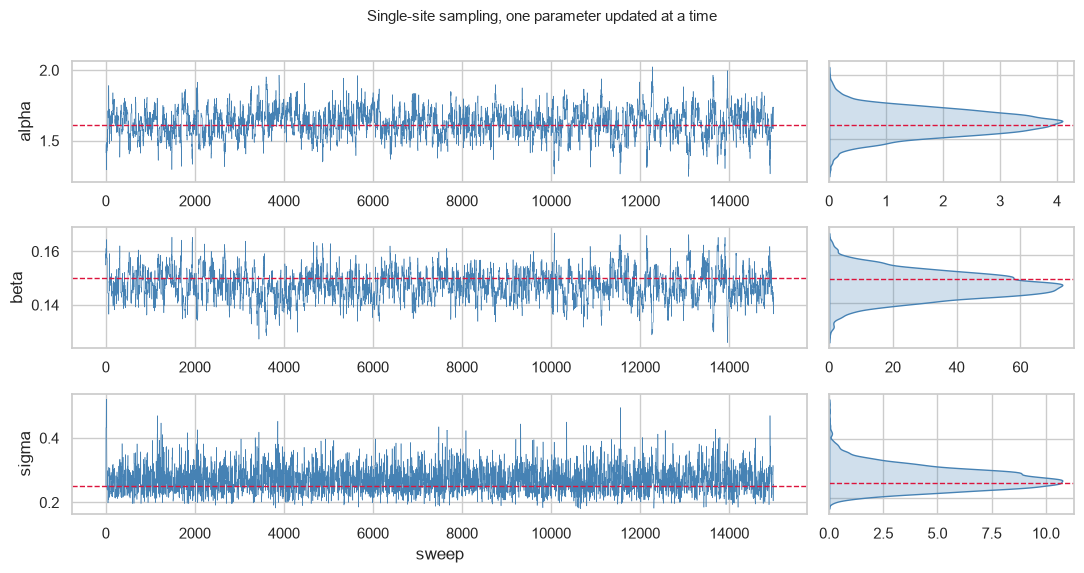

In [7]:
_ = plot_trace(samples, truth=truth, title="Single-site sampling, one parameter updated at a time")


## Single-site vs multi-site, uncentered vs centered

If we recall the linear model, where $\alpha$ is the intercept and $\beta$ is the slope, it is easy to imagine that nudging the value of $\alpha$ changes the appropriateness of $\beta$. They are dependent on each other, and we can confirm that they are strongly correlated. As the single-site scheme updates one parameter before the other, there exists inefficiency in the random walk. There are two ways in which we could mitigate this.

We could sample, evaluate and propose updates for $\alpha$ and $\beta$ simultaneously. This is multi-site sampling.

```python
run(..., groups=[["alpha", "beta"]])
```

Or we could transform the observed data, such that the days $x_i$ are centered by the mean day, i.e. days 1,2,...31 become days -15,...,0,...,15.

- $\mu_i = \alpha + \beta (x_i - \bar{x})$: $\alpha,\beta$ almost independent
- $\mu_i = \alpha + \beta x_i$: $\alpha,\beta$ correlated



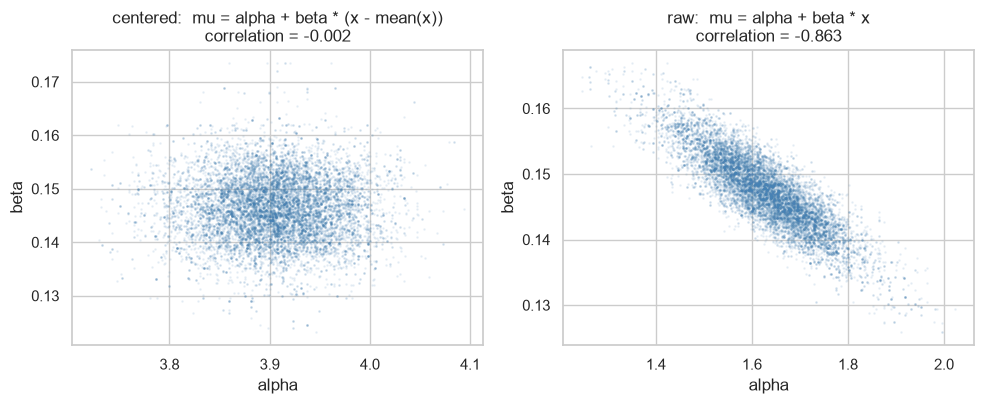

In [8]:
def fit(predictor, groups=None, draws=DRAWS):
    #Fit model variants
    a, b, s = Normal(0.0, 1.0), Normal(0.0, 1.0), Gamma(1.0, 1.0)
    leaf = Normal(a + b * predictor, s)
    drawn, _ = run(
        leaves=leaf,
        parameters={"alpha": a, "beta": b, "sigma": s},
        observed={leaf: y_obs},
        initial={"alpha": 0.0, "beta": 0.0, "sigma": 1.0},
        num_samples=draws,
        groups=groups,
    )
    return drawn


PAIR = [["alpha", "beta"]]
fits = {
    ("centered", "single"): fit(x_i - x_i.mean()),
    ("centered", "grouped"): fit(x_i - x_i.mean(), PAIR),
    ("raw", "single"): fit(x_i),
    ("raw", "grouped"): fit(x_i, PAIR),
}

#The posterior shape each sampler has to explore
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, kind in zip(axes, ["centered", "raw"]):
    drawn = fits[(kind, "single")]
    a_draws = np.asarray(drawn.alpha)[BURN:]
    b_draws = np.asarray(drawn.beta)[BURN:]
    ax.scatter(a_draws, b_draws, s=1, alpha=0.08, color="steelblue")
    ax.set(
        xlabel="alpha", ylabel="beta",
        title=f"{kind}:  mu = alpha + beta * {'(x - mean(x))' if kind == 'centered' else 'x'}\n"
              f"correlation = {np.corrcoef(a_draws, b_draws)[0, 1]:+.3f}",
    )

fig.tight_layout()


In [9]:
header = f"{'posterior':>10s}{'sampler':>10s}"
for n in ("alpha", "beta", "sigma"):
    header += f"{n + ' mean':>12s}{n + ' sd':>10s}{n + ' ESS':>10s}"
print(header)

ess = {}
for (kind, style), drawn in fits.items():
    post = {n: np.asarray(getattr(drawn, n))[BURN:] for n in ("alpha", "beta", "sigma")}
    stacked = np.stack([post[n] for n in ("alpha", "beta", "sigma")], -1)
    values = np.asarray(tfp.mcmc.effective_sample_size(stacked), dtype=float)
    ess[(kind, style)] = values

    row = f"{kind:>10s}{style:>10s}"
    for i, n in enumerate(("alpha", "beta", "sigma")):
        row += f"{post[n].mean():12.4f}{post[n].std():10.4f}{values[i]:10.0f}"
    print(row)

 posterior   sampler  alpha mean  alpha sd alpha ESS   beta mean   beta sd  beta ESS  sigma mean  sigma sd sigma ESS
  centered    single      3.9045    0.0497      2906      0.1464    0.0058      2073      0.2704    0.0387      2381
  centered   grouped      3.9067    0.0513      2272      0.1465    0.0059       793      0.2697    0.0389      1994
       raw    single      1.6263    0.0977       474      0.1474    0.0055       452      0.2689    0.0385      2114
       raw   grouped      1.6250    0.1049       908      0.1475    0.0059       961      0.2703    0.0386      1843


In [10]:
print(f"{'posterior':>10s}{'sampler':>10s}{'ESS alpha':>11s}{'ESS beta':>10s}{'ESS sigma':>11s}")
ess = {}
for (kind, style), drawn in fits.items():
    stacked = np.stack([np.asarray(getattr(drawn, n))[BURN:] for n in ("alpha", "beta", "sigma")], -1)
    values = np.asarray(tfp.mcmc.effective_sample_size(stacked), dtype=float)
    ess[(kind, style)] = values
    print(f"{kind:>10s}{style:>10s}{values[0]:11.0f}{values[1]:10.0f}{values[2]:11.0f}")

print("\nCompared to single site sampling...")
for kind in ("centered", "raw"):
    ratio = ess[(kind, "grouped")][:2].mean() / ess[(kind, "single")][:2].mean()
    verdict = f"grouping is {ratio:.1f}x BETTER" if ratio > 1 else f"grouping is {1 / ratio:.1f}x WORSE"
    print(f"{kind:>8s} posterior:  {verdict}")


 posterior   sampler  ESS alpha  ESS beta  ESS sigma
  centered    single       2906      2073       2381
  centered   grouped       2272       793       1994
       raw    single        474       452       2114
       raw   grouped        908       961       1843

Compared to single site sampling...
centered posterior:  grouping is 1.6x WORSE
     raw posterior:  grouping is 2.0x BETTER


Grouping is useful on the highly correlated data, but not so much on independent data.

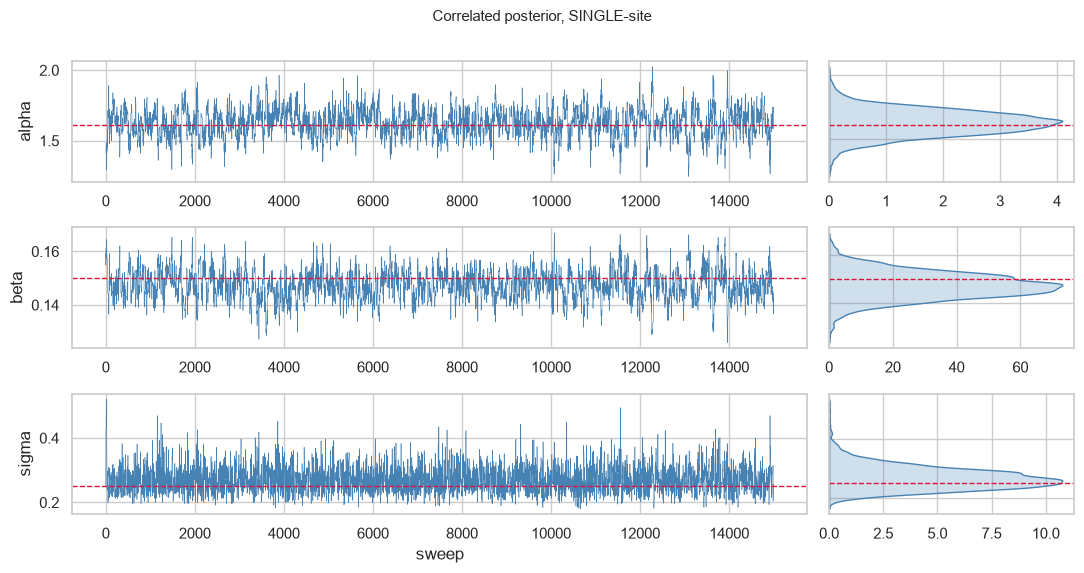

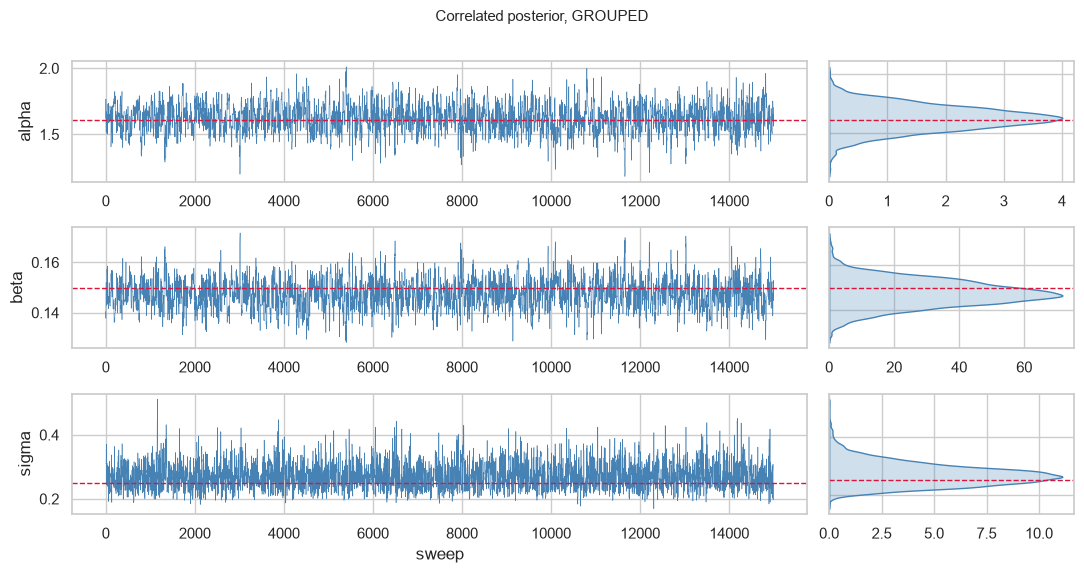

In [11]:
truth_raw = {"alpha": TRUE_ALPHA_DAY0, "beta": TRUE_BETA, "sigma": TRUE_SIGMA}

_ = plot_trace(fits[("raw", "single")], truth=truth_raw, title="Correlated posterior, SINGLE-site") #alpha, beta updated separately thus unstable
_ = plot_trace(fits[("raw", "grouped")], truth=truth_raw, title="Correlated posterior, GROUPED") #alpha, beta updated together


The traceplots for uncentered/correlated suggest that grouping improves the quality of mixing.
Densities produced by single and grouped sampling still concur, although grouped density overall smoother.


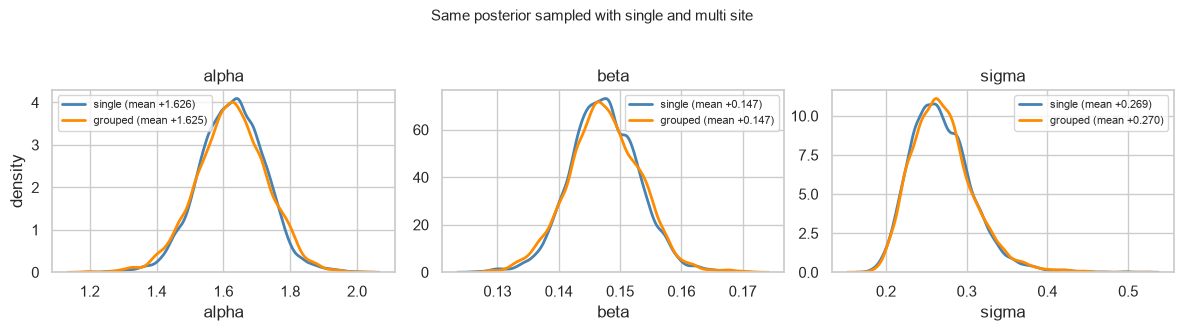

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, name in zip(axes, ("alpha", "beta", "sigma")):
    for style, colour in [("single", "steelblue"), ("grouped", "darkorange")]:
        d = np.asarray(getattr(fits[("raw", style)], name))[BURN:]
        sns.kdeplot(x=d, ax=ax, color=colour, lw=2, label=f"{style} (mean {d.mean():+.3f})")
    ax.set(title=name, xlabel=name, ylabel="density" if name == "alpha" else "")
    ax.legend(fontsize=8)
fig.suptitle("Same posterior sampled with single and multi site", y=1.03, fontsize=11)
fig.tight_layout()
